# Factores asociados al ingreso de los clientes de NovaRetail+

**Proyecto del Bootcamp de Análisis de Datos de TripleTen (2026)**

NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [1]:
# Importar librerías
import glob
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pointbiserialr, chi2_contingency


### Cargar Dataset

In [2]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [3]:
# mostrar las primeras 5 filas
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna `edad` está como `float64`, aunque solo contiene años enteros, por lo que se convierte a entero. `satisfaccion` se mantiene como decimal, porque incluye valores como 3,9.


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional. `id_cliente` es un identificador (por ejemplo, `CL-100000`) y no se usa en los cálculos.

In [4]:
# Corregir el tipo de dato
# edad está como float64, pero solo contiene años enteros
print('¿Todas las edades son enteras?', (df['edad'] % 1 == 0).all())
df['edad'] = df['edad'].astype(int)

¿Todas las edades son enteras? True


In [5]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [6]:
# Estadísticas descriptivas de variables numéricas
cols_num = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes',
            'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']

df[cols_num].describe().T

,count,mean,std,min,25%,50%,75%,max
edad,15000.0,38.262400,11.492378,18.0,30.0000,38.000,46.0000,75.00
nivel_ingreso,15000.0,30019.704782,9833.166305,8000.0,23127.0975,30023.745,36768.4400,74790.84
visitas_mes,15000.0,10.029000,3.158189,1.0,8.0000,10.000,12.0000,25.00
compras_mes,15000.0,1.206467,1.105284,0.0,0.0000,1.000,2.0000,8.00
gasto_publicidad_dirigida,15000.0,20.149301,10.880724,0.0,12.3100,19.730,27.2925,75.51
satisfaccion,15000.0,3.603693,0.685300,1.0,3.1000,3.600,4.1000,5.00
ingreso_anual,15000.0,36.594180,34.484888,0.0,0.0000,30.705,58.2200,244.69


**Diagnóstico inicial de variables numéricas**

- `edad` — entre 18 y 75 años, con media y mediana de 38. Distribución centrada y sin valores imposibles.
- `nivel_ingreso` — entre 8.000 y 74.791, con media y mediana cercanas a 30.000. Hay valores altos, pero plausibles.
- `visitas_mes` — entre 1 y 25 visitas, con mediana de 10.
- `compras_mes` — entre 0 y 8 compras, con mediana de 1. El 30,4 % de los clientes no compró en el mes.
- `gasto_publicidad_dirigida` — entre 0 y 75,51, con mediana de 19,73. Algunos clientes no recibieron inversión publicitaria.
- `satisfaccion` — entre 1 y 5, con decimales y media de 3,6.
- `ingreso_anual` — entre 0 y 244,69. La media (36,6) es mayor que la mediana (30,7), lo que indica un sesgo a la derecha, y el 30,4 % de los clientes tiene ingreso 0, que son exactamente los clientes sin compras.

#### Explorar variables binarias

In [7]:
# Verificar que cada columna tenga únicamente dos valores posibles
cols_bin = ['miembro_premium', 'abandono']

for col in cols_bin:
    print(f'{col}: valores únicos = {sorted(df[col].unique())}')
    print(df[col].value_counts(normalize=True).mul(100).round(2), '\n')

miembro_premium: valores únicos = [0, 1]
0    86.07
1    13.93
Name: miembro_premium, dtype: float64 

abandono: valores únicos = [0, 1]
0    84.93
1    15.07
Name: abandono, dtype: float64 



**Diagnóstico inicial de variables binarias**

- `miembro_premium` — solo tiene los valores 0 y 1. El 13,93 % de los clientes es premium, así que la variable está desbalanceada.
- `abandono` — solo tiene los valores 0 y 1. El 15,07 % de los clientes abandonó la plataforma, también una variable desbalanceada.

#### Explorar variables categóricas

In [8]:
# Verificar el número de valores únicos por variable categórica
cols_cat = ['id_cliente', 'tipo_dispositivo', 'region']
df[cols_cat].nunique()

id_cliente          15000
tipo_dispositivo        3
region                  4
dtype: int64

In [9]:
# Explorar variables categóricas y cómo se distribuyen
for col in ['tipo_dispositivo', 'region']:
    print(df[col].value_counts(normalize=True).mul(100).round(2), '\n')

móvil         65.45
escritorio    24.80
tablet         9.75
Name: tipo_dispositivo, dtype: float64 

norte    29.30
oeste    25.40
sur      24.84
este     20.46
Name: region, dtype: float64 



**Diagnóstico inicial de variables categóricas**

- `id_cliente` — tiene 15.000 valores únicos, uno por registro, así que no hay clientes duplicados.
- `tipo_dispositivo` — 3 categorías: móvil concentra el 65,45 % de los clientes, seguido de escritorio (24,80 %) y tablet (9,75 %).
- `region` — 4 categorías bastante equilibradas: norte (29,30 %), oeste (25,40 %), sur (24,84 %) y este (20,46 %).

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

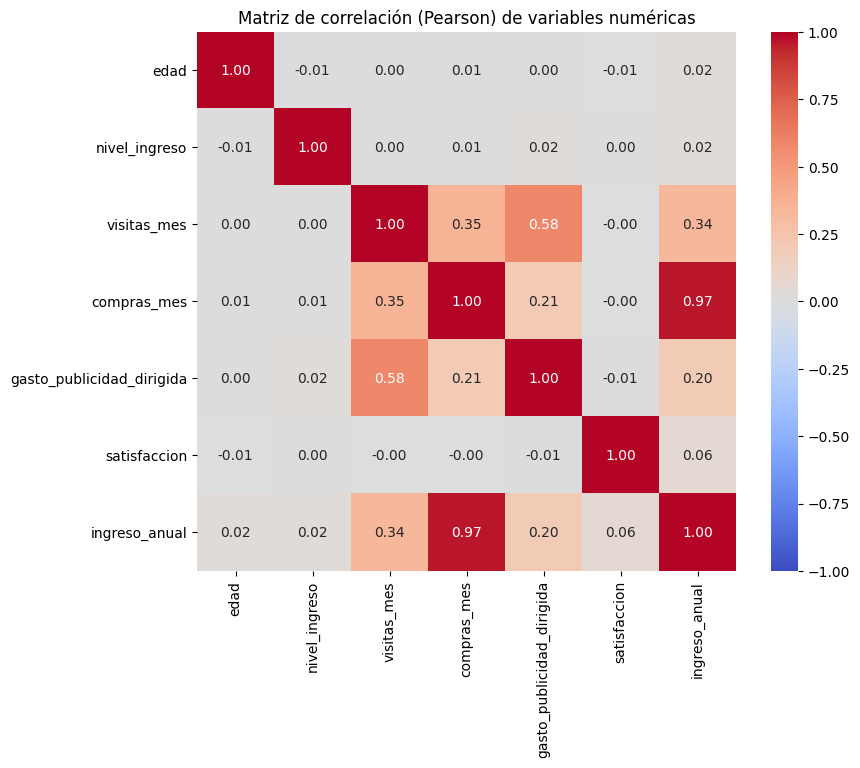

In [10]:
# Visualizar la matriz de correlación para identificar relaciones
corr = df[cols_num].corr(method='pearson')

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Matriz de correlación (Pearson) de variables numéricas')
plt.show()

**Observaciones generales (Heatmap)**
- La mayoría de las correlaciones entre variables son débiles o casi nulas.
- Destacan tres relaciones: `compras_mes` con `ingreso_anual` (0,97, muy fuerte), `visitas_mes` con `gasto_publicidad_dirigida` (0,58, moderada) y `visitas_mes` con `compras_mes` (0,35, débil a moderada).
- `edad` y `nivel_ingreso` prácticamente no se relacionan con ninguna otra variable.


Observaciones respecto a `ingreso_anual`  
- Presenta una relación muy fuerte con `compras_mes` (0,97), moderada con `visitas_mes` (0,34) y débil con `gasto_publicidad_dirigida` (0,20).
- Su relación con `satisfaccion` (0,06), `edad` (0,02) y `nivel_ingreso` (0,02) es prácticamente nula.

### Scatterplot general

**Decisión:** se incluye un scatterplot general (pairplot) con una muestra de 2.000 clientes, para no saturar el gráfico. Permite ver todas las relaciones de un vistazo y confirma lo que muestra el heatmap: solo la relación entre `compras_mes` e `ingreso_anual` tiene una forma claramente lineal, mientras que el resto son nubes dispersas. También deja ver la acumulación de clientes con ingreso 0.

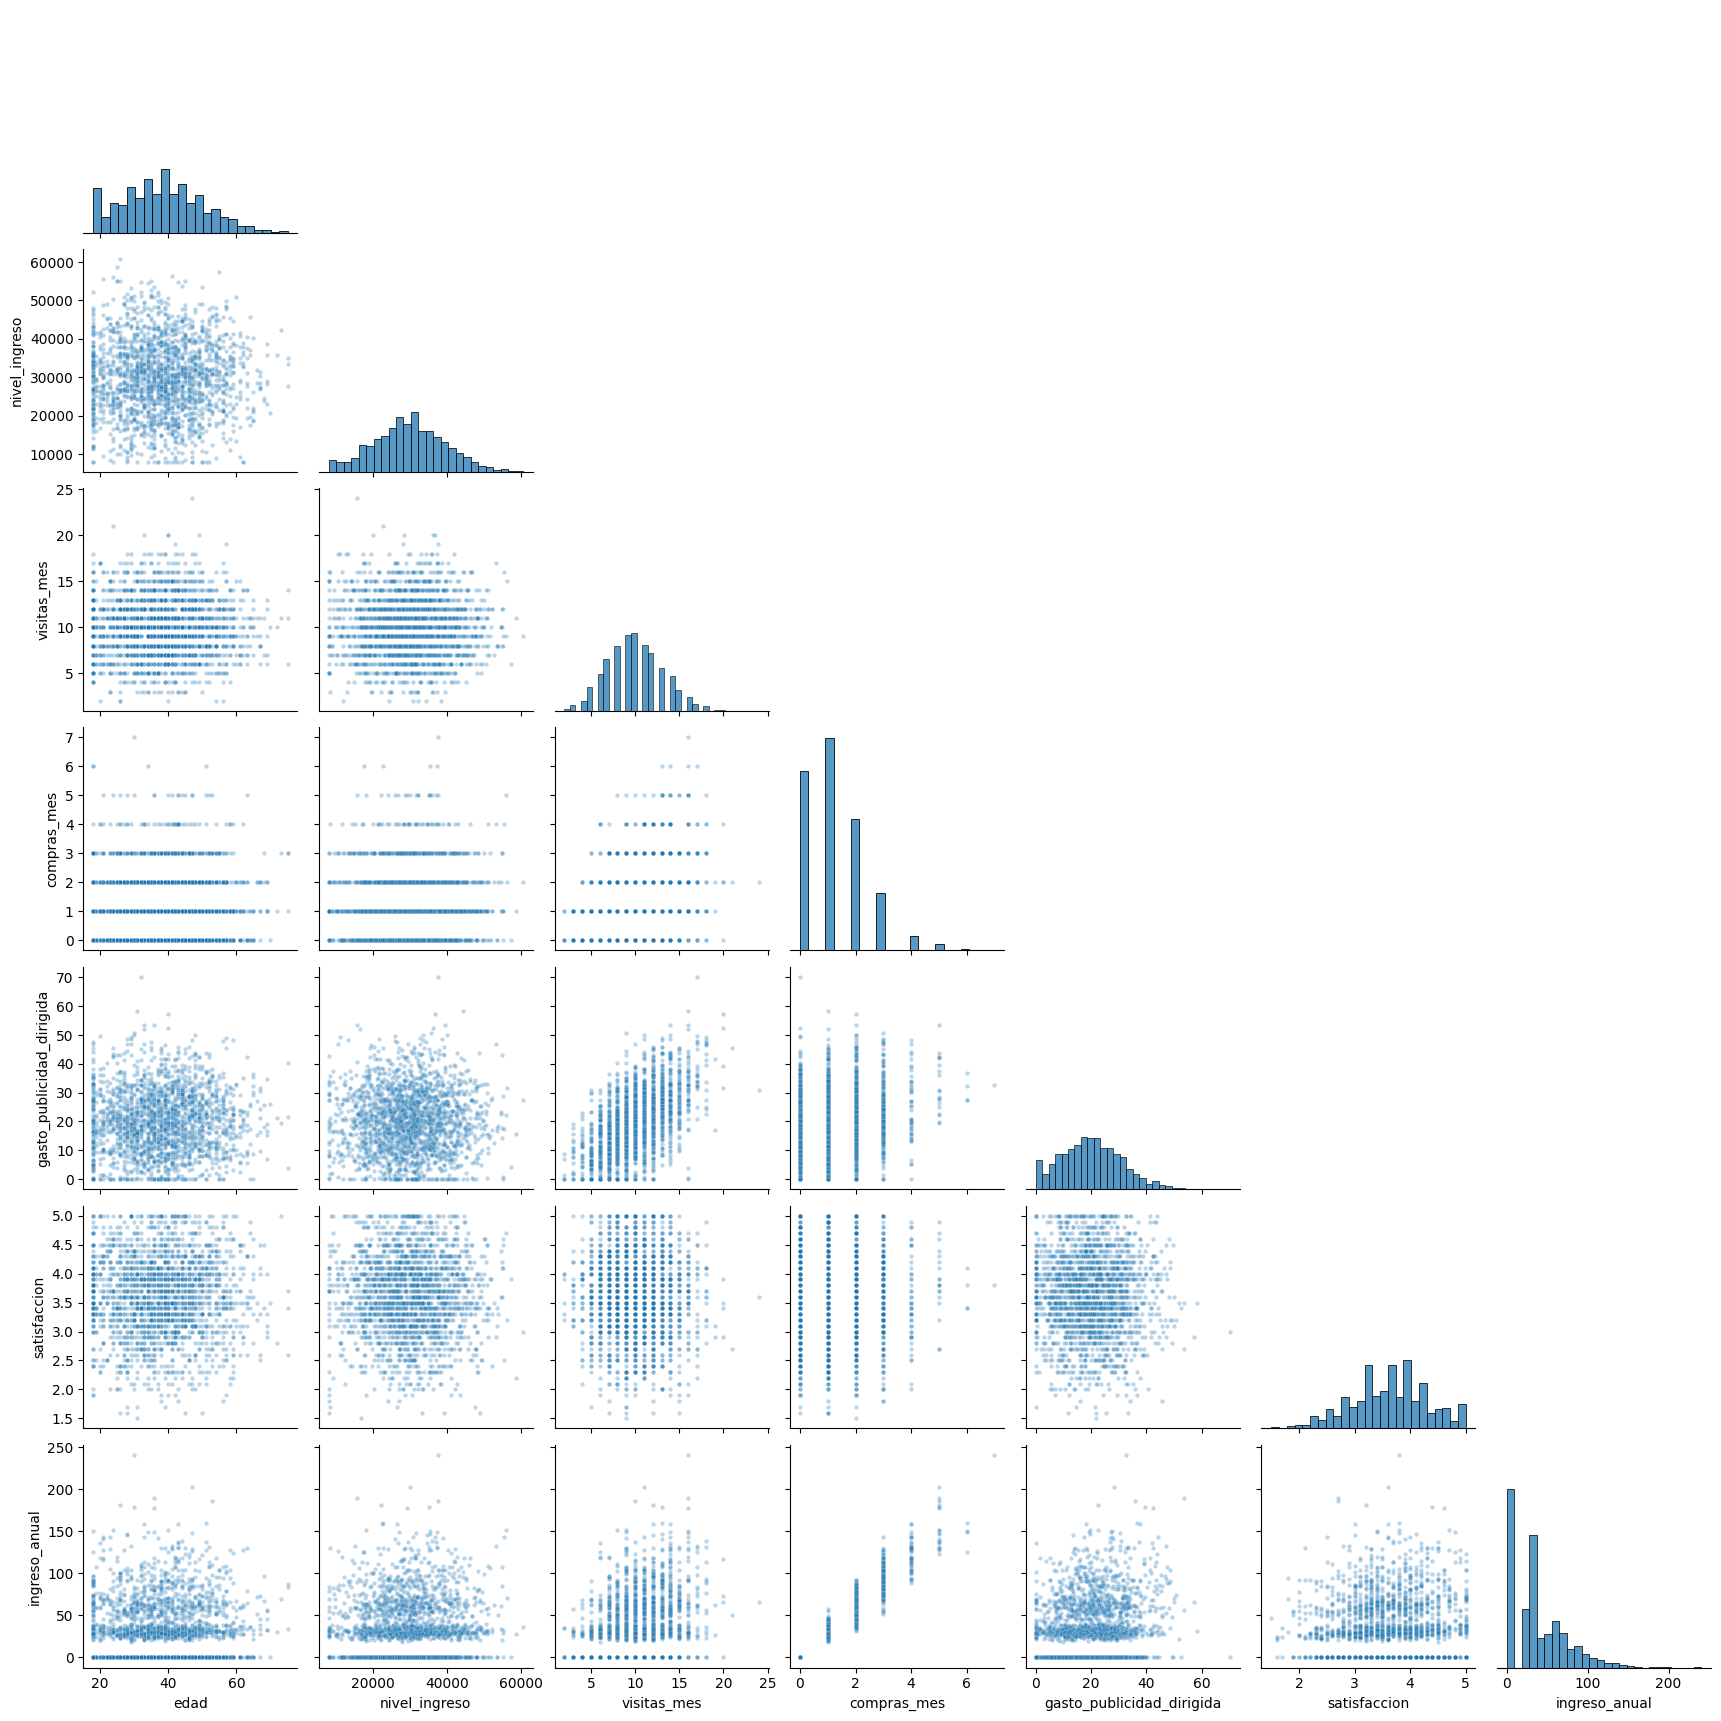

In [11]:
muestra = df.sample(2000, random_state=42)
sns.pairplot(muestra[cols_num], plot_kws={'alpha': 0.3, 's': 10}, corner=True)
plt.show()

### Scatterplot para pares clave

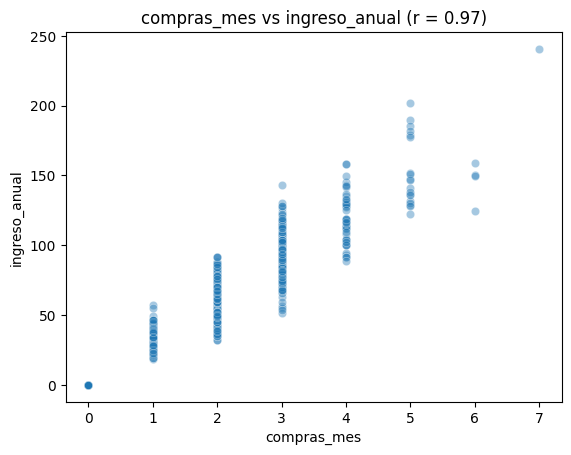

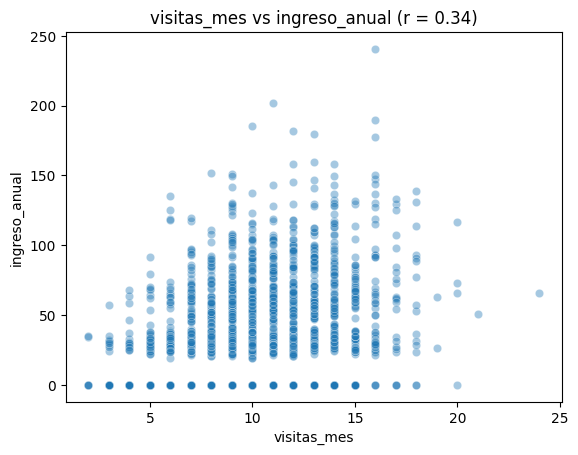

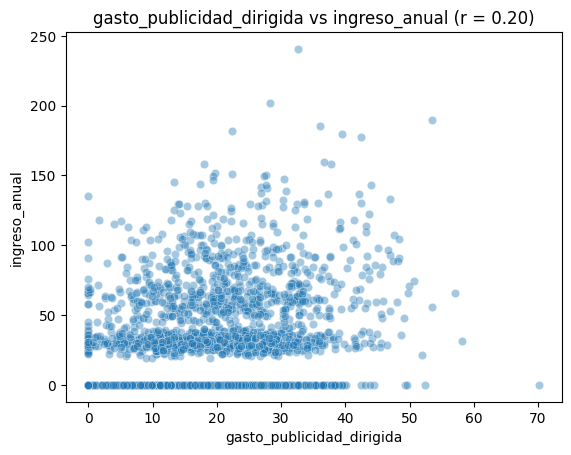

In [12]:
# Visualizar pares de variables con relaciones moderadas o fuertes
top_ingreso = corr['ingreso_anual'].drop('ingreso_anual').abs().sort_values(ascending=False).head(3).index

for col in top_ingreso:
    sns.scatterplot(data=muestra, x=col, y='ingreso_anual', alpha=0.4)
    plt.title(f'{col} vs ingreso_anual (r = {corr.loc[col, "ingreso_anual"]:.2f})')
    plt.show()

Pares con |r| >= 0.5: [('visitas_mes', 'gasto_publicidad_dirigida')]


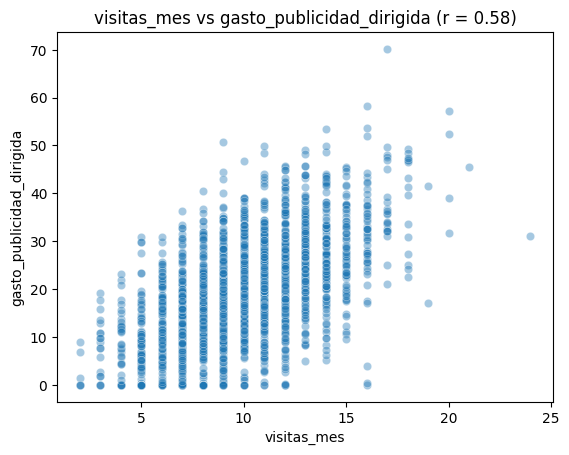

In [13]:
# Posible colinealidad: pares de variables explicativas con |r| >= 0.5
explicativas = [c for c in cols_num if c != 'ingreso_anual']
pares = [(a, b) for i, a in enumerate(explicativas) for b in explicativas[i + 1:]
         if abs(corr.loc[a, b]) >= 0.5]
print('Pares con |r| >= 0.5:', pares)

for a, b in pares:
    sns.scatterplot(data=muestra, x=a, y=b, alpha=0.4)
    plt.title(f'{a} vs {b} (r = {corr.loc[a, b]:.2f})')
    plt.show()

**Observaciones iniciales (Scatterplot)**

**`compras_mes` vs `ingreso_anual`**
- Dirección positiva y muy marcada: cada compra adicional suma, en promedio, unos 30 de ingreso.
- Dispersión baja: los puntos forman escalones, porque las compras son números enteros.
- Un posible outlier: un cliente con 7 compras e ingreso cercano a 240.

**`visitas_mes` vs `ingreso_anual`**
- Dirección positiva, pero débil a moderada.
- Dispersión alta: con el mismo número de visitas hay clientes con ingresos muy distintos, y en casi todos los niveles hay clientes con ingreso 0, que visitan pero no compran.

**`gasto_publicidad_dirigida` vs `ingreso_anual`**
- Dirección positiva débil.
- Dispersión alta: hay clientes con ingreso 0 en todos los niveles de gasto publicitario.

**`visitas_mes` vs `gasto_publicidad_dirigida`**
- Dirección positiva moderada y dispersión media.
- Posible colinealidad entre ambas variables (0,58): a los clientes que más visitan se les asigna más publicidad, o viceversa.

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [14]:
# Calcular correlación entre variables relevantes
corr_spearman = df[cols_num].corr(method='spearman')

tabla_ingreso = pd.DataFrame({
    'pearson': corr['ingreso_anual'],
    'spearman': corr_spearman['ingreso_anual']
}).drop('ingreso_anual').round(3)

tabla_ingreso.sort_values('pearson', key=abs, ascending=False)

,pearson,spearman
compras_mes,0.967,0.967
visitas_mes,0.337,0.321
gasto_publicidad_dirigida,0.197,0.185
satisfaccion,0.056,0.061
edad,0.017,0.016
nivel_ingreso,0.017,0.025


In [15]:
# Calcular correlación entre variables relevantes
filas = []
for i, a in enumerate(explicativas):
    for b in explicativas[i + 1:]:
        r_p = corr.loc[a, b]
        r_s = corr_spearman.loc[a, b]
        if abs(r_p) >= 0.3 or abs(r_s) >= 0.3:
            filas.append({'var1': a, 'var2': b, 'pearson': round(r_p, 3), 'spearman': round(r_s, 3)})

pd.DataFrame(filas).sort_values('pearson', key=abs, ascending=False) if filas else 'No hay pares con |r| >= 0.3'

,var1,var2,pearson,spearman
1,visitas_mes,gasto_publicidad_dirigida,0.579,0.559
0,visitas_mes,compras_mes,0.354,0.333


**Observaciones de correlación**

Pearson y Spearman dan valores casi iguales en todos los casos, lo que indica relaciones aproximadamente lineales y sin un efecto fuerte de outliers.

**`compras_mes` vs `ingreso_anual`**
- Correlación positiva muy fuerte (Pearson 0,967 y Spearman 0,967).
- Es casi una relación directa: el ingreso anual se construye a partir del número de compras.

**`visitas_mes` y `gasto_publicidad_dirigida` vs `ingreso_anual`**
- `visitas_mes`: positiva y moderada (0,337 y 0,321).
- `gasto_publicidad_dirigida`: positiva y débil (0,197 y 0,185).
- `satisfaccion`, `edad` y `nivel_ingreso`: prácticamente nulas (0,056 o menos).

**Colinealidad entre variables explicativas**
- `visitas_mes` vs `gasto_publicidad_dirigida`: moderada (0,579 y 0,559).
- `visitas_mes` vs `compras_mes`: débil a moderada (0,354 y 0,333).
- Como las dos relaciones están por debajo de 0,7, no hay colinealidad fuerte, pero estas variables comparten información y no deben interpretarse por separado.

### Punto-biserial

In [16]:
# Calcular correlación entre variables relevantes
resultados = []
for b in cols_bin:
    for col in cols_num:
        r, p = pointbiserialr(df[b], df[col])
        resultados.append({'binaria': b, 'numerica': col, 'r_pb': round(r, 3), 'p_valor': round(p, 4)})

tabla_pb = pd.DataFrame(resultados)
tabla_pb.sort_values('r_pb', key=abs, ascending=False)

,binaria,numerica,r_pb,p_valor
6,miembro_premium,ingreso_anual,0.093,0.0000
5,miembro_premium,satisfaccion,0.026,0.0016
12,abandono,satisfaccion,-0.024,0.0035
2,miembro_premium,visitas_mes,-0.013,0.1211
7,abandono,edad,-0.012,0.1590
9,abandono,visitas_mes,-0.009,0.2734
10,abandono,compras_mes,0.008,0.3099
1,miembro_premium,nivel_ingreso,-0.006,0.4930
8,abandono,nivel_ingreso,0.006,0.4722
0,miembro_premium,edad,0.005,0.5728


**Observaciones Punto-biserial**

**`miembro_premium` vs `ingreso_anual`**
- Relación positiva y débil (0,093), pero estadísticamente significativa (p < 0,001). Es la asociación más alta entre las binarias.

**`abandono` vs `ingreso_anual`**
- Relación nula (−0,003, p = 0,73): los clientes que abandonaron generaban, en promedio, el mismo ingreso que los que se quedaron.

**`abandono` y `miembro_premium` vs `satisfaccion`**
- Relaciones muy débiles: −0,024 con abandono y 0,026 con premium. Son significativas por el tamaño de la muestra, pero su magnitud es demasiado pequeña para tener relevancia práctica.

El resto de las relaciones son prácticamente nulas (|r| < 0,02 y p > 0,05).

### V de Cramér

In [17]:
# Función para calcular V de Cramér
def cramers_v(x, y):
    tabla = pd.crosstab(x, y)
    chi2 = chi2_contingency(tabla)[0]
    n = tabla.to_numpy().sum()
    k = min(tabla.shape) - 1
    return np.sqrt(chi2 / (n * k))

In [18]:
# Aplicar V de Cramér en variables relevantes
# ingreso_anual tiene más del 25 % de ceros, por lo que no se puede dividir en cuartiles iguales.
# Se crean 4 niveles: 'Sin ingreso' (0) y terciles del resto (Bajo, Medio, Alto)
print('Clientes con ingreso_anual = 0:', (df['ingreso_anual'] == 0).sum(),
      f"({(df['ingreso_anual'] == 0).mean():.1%})")
print('¿Coinciden con los clientes sin compras?', ((df['ingreso_anual'] == 0) == (df['compras_mes'] == 0)).all())

df['nivel_ingreso_anual'] = 'Sin ingreso'
positivos = df['ingreso_anual'] > 0
df.loc[positivos, 'nivel_ingreso_anual'] = pd.qcut(df.loc[positivos, 'ingreso_anual'], 3,
                                                    labels=['Bajo', 'Medio', 'Alto']).astype(str)
print(df['nivel_ingreso_anual'].value_counts(), '\n')

pares_cat = [
    ('tipo_dispositivo', 'region'),
    ('tipo_dispositivo', 'nivel_ingreso_anual'),
    ('region', 'nivel_ingreso_anual'),
    ('tipo_dispositivo', 'abandono'),
    ('region', 'abandono'),
    ('tipo_dispositivo', 'miembro_premium'),
    ('region', 'miembro_premium'),
]

tabla_v = pd.DataFrame([{'var1': a, 'var2': b, 'v_cramer': round(cramers_v(df[a], df[b]), 3)} for a, b in pares_cat])
print(tabla_v.sort_values('v_cramer', ascending=False))

# Ingreso anual promedio por segmento, como apoyo para la interpretación
for col in ['tipo_dispositivo', 'region', 'miembro_premium', 'abandono']:
    print('\n', df.groupby(col)['ingreso_anual'].agg(['mean', 'median', 'count']).round(1))

Clientes con ingreso_anual = 0: 4567 (30.4%)
¿Coinciden con los clientes sin compras? True
Sin ingreso    4567
Bajo           3480
Alto           3477
Medio          3476
Name: nivel_ingreso_anual, dtype: int64 

               var1                 var2  v_cramer
5  tipo_dispositivo      miembro_premium     0.020
1  tipo_dispositivo  nivel_ingreso_anual     0.017
2            region  nivel_ingreso_anual     0.015
4            region             abandono     0.015
6            region      miembro_premium     0.013
0  tipo_dispositivo               region     0.012
3  tipo_dispositivo             abandono     0.007

                   mean  median  count
tipo_dispositivo                     
escritorio        36.4    30.4   3720
móvil             36.6    30.7   9818
tablet            37.1    31.3   1462

         mean  median  count
region                     
este    36.9    30.8   3069
norte   36.7    30.7   4395
oeste   35.7    30.4   3810
sur     37.1    30.9   3726

                

**Observaciones V de Cramér**

- Todas las asociaciones entre variables categóricas son prácticamente nulas: el valor más alto es 0,020 (tipo_dispositivo vs miembro_premium), muy por debajo de 0,1, el umbral habitual de una asociación débil.
- Dispositivo y región vs nivel de ingreso anual (0,017 y 0,015): el nivel de ingreso que genera un cliente no depende del dispositivo que usa ni de su región. Los promedios lo confirman: entre 36,4 y 37,1 por dispositivo y entre 35,7 y 37,1 por región.
- Dispositivo y región vs abandono (0,007 y 0,015): el abandono se reparte de forma similar en todos los dispositivos y regiones.
- Dispositivo y región vs membresía premium (0,020 y 0,013): la proporción de clientes premium es parecida en todos los segmentos.
- Dispositivo vs región (0,012): las dos variables son independientes; por ejemplo, el uso del móvil predomina por igual en todas las regiones.

Para comparar el ingreso con variables categóricas, `ingreso_anual` se agrupó en cuatro niveles: "Sin ingreso" (4.567 clientes, el 30,4 %, que coinciden exactamente con los clientes sin compras) y terciles del resto (Bajo, Medio y Alto).

## Sección 5 - Interpretación de resultados para el negocio

### Hallazgo 1 — El número de compras explica casi todo el ingreso

**Evidencia visual:** scatterplot de `compras_mes` vs `ingreso_anual`, con puntos alineados en escalones ascendentes.  
**Evidencia numérica:** correlación de 0,967 (Pearson y Spearman).

**Interpretación**  
El ingreso de cada cliente depende casi por completo de cuántas compras hace, con un valor relativamente estable por compra (unos 30). Los clientes con ingreso 0 son, en todos los casos, los que no compraron.

**No podemos afirmar**  
Que cualquier acción que aumente las compras vaya a aumentar el ingreso en la misma proporción, ni qué factores llevan a un cliente a comprar más. Además, esta relación es casi mecánica, porque el ingreso se calcula a partir de las compras.

**Implicación de negocio**  
La palanca principal es la frecuencia de compra, no el valor de cada compra. Las estrategias de crecimiento deberían enfocarse en convertir a los clientes que no compran y en aumentar las compras de los que ya compran.

### Hallazgo 2 — Las visitas y la publicidad se asocian con el ingreso de forma indirecta

**Evidencia visual:** scatterplots de `visitas_mes` y `gasto_publicidad_dirigida` vs `ingreso_anual` (nubes dispersas con tendencia positiva) y de `visitas_mes` vs `gasto_publicidad_dirigida`.  
**Evidencia numérica:** visitas vs ingreso = 0,337; publicidad vs ingreso = 0,197; publicidad vs visitas = 0,579; visitas vs compras = 0,354.

**Interpretación**  
Se observa una cadena: los clientes con más publicidad dirigida tienden a visitar más, y los que visitan más tienden a comprar algo más. Pero la relación entre visitas y compras es solo moderada, y muchos clientes visitan la plataforma sin comprar.

**No podemos afirmar**  
Que la publicidad cause más visitas o más ingreso. Es posible que la publicidad se asigne precisamente a los usuarios que ya visitan más, lo que crearía la correlación sin que la publicidad tenga efecto.

**Implicación de negocio**  
Antes de aumentar el presupuesto de publicidad dirigida, conviene medir su efecto real con un experimento (prueba A/B). Además, existe una oportunidad en mejorar la conversión de las visitas en compras.

### Hallazgo 3 — El perfil demográfico y la satisfacción casi no se relacionan con el ingreso

**Evidencia visual:** heatmap, donde `edad`, `nivel_ingreso` y `satisfaccion` muestran valores cercanos a 0 con `ingreso_anual`.  
**Evidencia numérica:** edad = 0,017; nivel de ingreso = 0,017; satisfacción = 0,056.

**Interpretación**  
Cuánto ingreso genera un cliente no depende de su edad ni de cuánto gana, y casi no depende de su satisfacción declarada. Lo que diferencia a los clientes es su comportamiento en la plataforma.

**No podemos afirmar**  
Que estas variables no influyan en otros resultados, como la fidelidad o el tipo de producto comprado, ni que la satisfacción no importe, ya que podría actuar a largo plazo.

**Implicación de negocio**  
Segmentar a los clientes por comportamiento (visitas y compras) es más útil que segmentarlos por edad o nivel de ingreso para campañas orientadas a aumentar el ingreso.

### Hallazgo 4 — Los clientes premium generan más ingreso, y el abandono afecta a todos los niveles de valor

**Evidencia visual:** no aplica (variables binarias).  
**Evidencia numérica:** premium vs ingreso = 0,093 (p < 0,001); ingreso promedio de 44,6 en premium frente a 35,3 en no premium. Abandono vs ingreso = −0,003 (p = 0,73); ingreso promedio de 36,4 en quienes abandonaron frente a 36,6 en quienes se quedaron.

**Interpretación**  
Los clientes premium generan, en promedio, un 26 % más de ingreso. La correlación es baja porque solo el 14 % de los clientes es premium y el ingreso varía mucho entre clientes, pero la diferencia entre grupos es relevante. En cambio, los clientes que abandonan generaban prácticamente el mismo ingreso que los que se quedan, así que la plataforma pierde clientes de todos los niveles de valor.

**No podemos afirmar**  
Que la membresía premium cause un mayor ingreso: es posible que los clientes que ya compraban más sean quienes deciden suscribirse. Tampoco sabemos por qué abandonan los clientes.

**Implicación de negocio**  
Vale la pena estudiar si conviene impulsar la membresía premium, empezando por una prueba controlada antes de una campaña masiva. Y las acciones de retención no deberían limitarse a los clientes de menor gasto, porque los que abandonan valen lo mismo que los que se quedan.

## Sección 6 - Limitaciones y próximos pasos

### **Limitaciones**
- Correlación ≠ causalidad: ninguno de los hallazgos demuestra que una variable provoque cambios en otra.
- El ingreso anual se calcula prácticamente a partir de las compras, así que su correlación casi perfecta no explica por qué los clientes compran más.
- El 30,4 % de los clientes tiene ingreso 0, lo que afecta a las correlaciones de Pearson y dificulta dividir el ingreso en grupos iguales.
- Los datos son una fotografía de un solo momento (2024), por lo que no permiten ver cambios en el tiempo.
- La publicidad dirigida probablemente no se asigna al azar, lo que puede generar correlaciones engañosas.
- Faltan variables relevantes, como el precio, la categoría de producto o las campañas activas.

### **Próximos pasos** 

Probar segmentación adicional
- Analizar a los clientes que visitan mucho pero no compran, para identificar barreras de conversión.
- Comparar el ingreso y el abandono por dispositivo y región.

Medir el efecto de la publicidad
- Diseñar una prueba A/B que asigne la publicidad dirigida al azar.

Modelar el abandono y el ingreso
- Construir una regresión multivariable para el ingreso y un modelo de clasificación para el abandono, que controlen la relación entre variables.